
# Volatilidade e Correlações

## 1. Pergunta de pesquisa

A volatilidade dos retornos do Ibovespa apresenta comportamento constante ao longo do tempo ou existem períodos de maior instabilidade? Os retornos financeiros apresentam dependência temporal, especialmente em suas magnitudes?

## 2. Objetivos

- Estimar a volatilidade histórica dos retornos.
- Investigar a evolução da volatilidade por meio de janelas móveis.
- Analisar a autocorrelação dos retornos.
- Investigar a dependência temporal dos retornos absolutos e quadráticos.
- Identificar possíveis agrupamentos de volatilidade (*volatility clustering*).
- Relacionar os resultados aos conceitos de Física Estatística e processos estocásticos.

## 3. Fundamentação teórica

A volatilidade representa a dispersão dos retornos de um ativo financeiro e constitui uma medida importante de incerteza.

A autocorrelação permite investigar a dependência temporal de uma série, enquanto o estudo dos retornos absolutos e quadráticos possibilita identificar padrões de persistência na magnitude das oscilações.

O agrupamento de volatilidade ocorre quando períodos de grandes oscilações tendem a ser acompanhados por outras oscilações expressivas, assim como períodos de baixa volatilidade tendem a apresentar continuidade.

## 4. Dados e metodologia

A análise utiliza a série histórica do Ibovespa, previamente tratada e armazenada em `data/processed/ibovespa_tratado.csv`.

A variável principal será `Retorno_Log`.

Serão utilizadas estatísticas descritivas, janelas móveis, funções de autocorrelação e visualizações temporais.

In [22]:
# TODO: importar as bibliotecas necessárias e implementar a análise.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sys 
import sys
import statsmodels

from statsmodels.graphics.tsaplots import plot_acf

print("Python:", sys.executable)
print("Statsmodels:", statsmodels.__version__)

from pathlib import Path


Python: C:\Users\Mateus.RH\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe
Statsmodels: 0.15.0


In [23]:
import sys
import statsmodels
from statsmodels.graphics.tsaplots import plot_acf

print("Python:", sys.executable)
print("Statsmodels:", statsmodels.__version__)
print("Importação realizada com sucesso!")

Python: C:\Users\Mateus.RH\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe
Statsmodels: 0.15.0
Importação realizada com sucesso!


In [24]:
%pip install statsmodels

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: C:\Users\Mateus.RH\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [25]:
import sys

print(sys.executable)

C:\Users\Mateus.RH\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe


## 4. Resultados


In [26]:
raiz_projeto = Path.cwd()

if raiz_projeto.name == "notebooks":
    raiz_projeto = raiz_projeto.parent

arquivo = (
    raiz_projeto
    / "data"
    / "processed"
    / "ibovespa_tratado.csv"
)

dados = pd.read_csv(
    arquivo,
    index_col="Data",
    parse_dates=True
)

dados = dados.sort_index()

dados.head()

,Preco_Fechamento,Retorno_Simples,Retorno_Log
Data,,,
2015-01-05,47517.0,-0.020510,-0.020724
2015-01-06,48001.0,0.010186,0.010134
2015-01-07,49463.0,0.030458,0.030003
2015-01-08,49943.0,0.009704,0.009657
2015-01-09,48840.0,-0.022085,-0.022333


In [27]:
retornos = pd.to_numeric(
    dados["Retorno_Log"],
    errors="coerce"
)

retornos = (
    retornos
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
)

print("Quantidade de observações:", len(retornos))
print("Data inicial:", retornos.index.min())
print("Data final:", retornos.index.max())

retornos.describe()

Quantidade de observações: 2945
Data inicial: 2015-01-05 00:00:00
Data final: 2026-11-13 00:00:00


count    2945.000000
mean        0.000431
std         0.014888
min        -0.159930
25%        -0.007000
50%         0.000496
75%         0.008226
max         0.130223
Name: Retorno_Log, dtype: float64

In [28]:
media_retornos = retornos.mean()
volatilidade_historica = retornos.std()
variancia_historica = retornos.var()

print(f"Retorno médio: {media_retornos:.6f}")
print(f"Variância histórica: {variancia_historica:.8f}")
print(f"Volatilidade histórica: {volatilidade_historica:.6f}")
print(f"Volatilidade percentual: {volatilidade_historica * 100:.4f}%")

Retorno médio: 0.000431
Variância histórica: 0.00022165
Volatilidade histórica: 0.014888
Volatilidade percentual: 1.4888%


In [29]:
volatilidade_21 = retornos.rolling(window=21).std()
volatilidade_63 = retornos.rolling(window=63).std()

volatilidade_movel = pd.DataFrame({
    "Retorno_Log": retornos,
    "Volatilidade_21": volatilidade_21,
    "Volatilidade_63": volatilidade_63
})

volatilidade_movel.tail()

,Retorno_Log,Volatilidade_21,Volatilidade_63
Data,,,
2026-11-09,0.021936,0.034635,0.023855
2026-11-10,-0.005233,0.034412,0.023863
2026-11-11,0.004211,0.034163,0.023648
2026-11-12,-0.004287,0.034179,0.023653
2026-11-13,0.006597,0.034316,0.023663


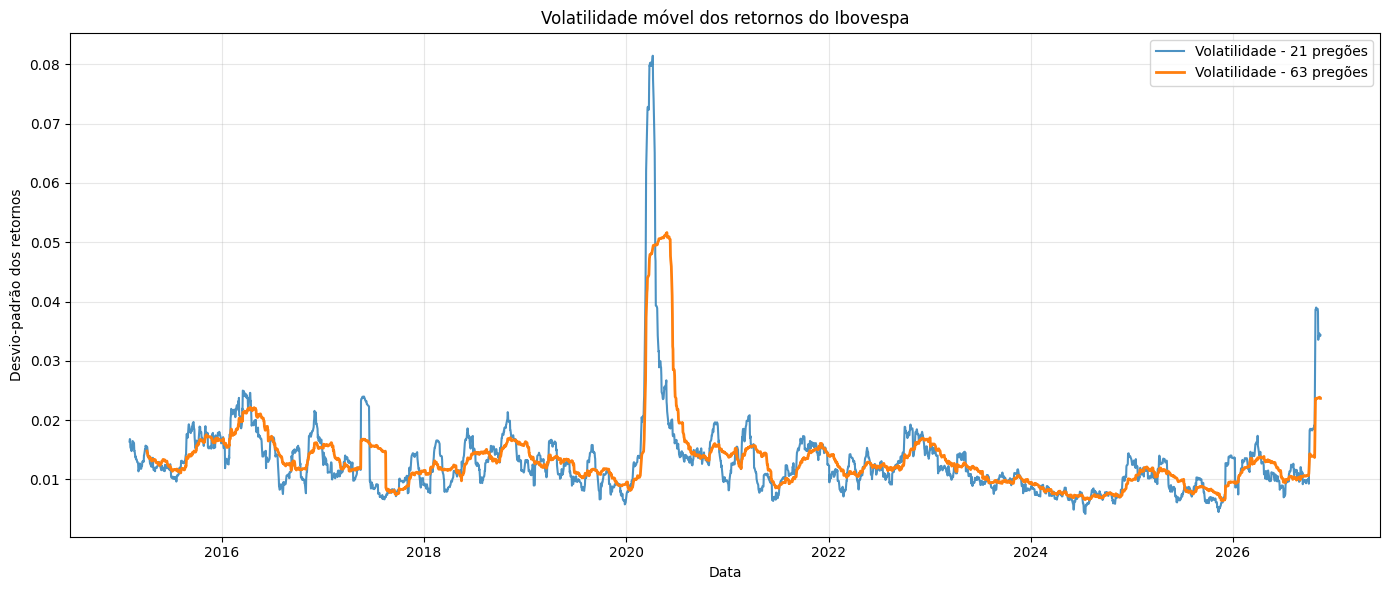

In [30]:
plt.figure(figsize=(14, 6))

plt.plot(
    volatilidade_21,
    label="Volatilidade - 21 pregões",
    alpha=0.8
)

plt.plot(
    volatilidade_63,
    label="Volatilidade - 63 pregões",
    linewidth=2
)

plt.title("Volatilidade móvel dos retornos do Ibovespa")
plt.xlabel("Data")
plt.ylabel("Desvio-padrão dos retornos")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [31]:
resumo_volatilidade = pd.DataFrame({
    "Volatilidade_21": volatilidade_21,
    "Volatilidade_63": volatilidade_63
})

resumo_volatilidade.describe()

,Volatilidade_21,Volatilidade_63
count,2925.000000,2883.000000
mean,0.012961,0.013267
std,0.007110,0.006297
min,0.004196,0.006423
25%,0.009485,0.010252
50%,0.011733,0.012181
75%,0.014650,0.014595
max,0.081449,0.051632


### Interpretação da volatilidade móvel

A análise da volatilidade móvel, calculada utilizando janelas de
21 e 63 pregões, apresentou médias relativamente próximas,
respectivamente 1,2961% e 1,3267%.

Entretanto, a volatilidade calculada com 21 pregões apresentou
maior dispersão e um valor máximo superior ao observado na
janela de 63 pregões.

Esse comportamento demonstra que janelas menores são mais
sensíveis às oscilações recentes do mercado, enquanto janelas
maiores tendem a suavizar variações de curto prazo.

Os resultados são compatíveis com a hipótese de que a
volatilidade financeira varia ao longo do tempo, não sendo
adequadamente representada apenas por uma medida constante.

# Autocorrelações dos retornos 

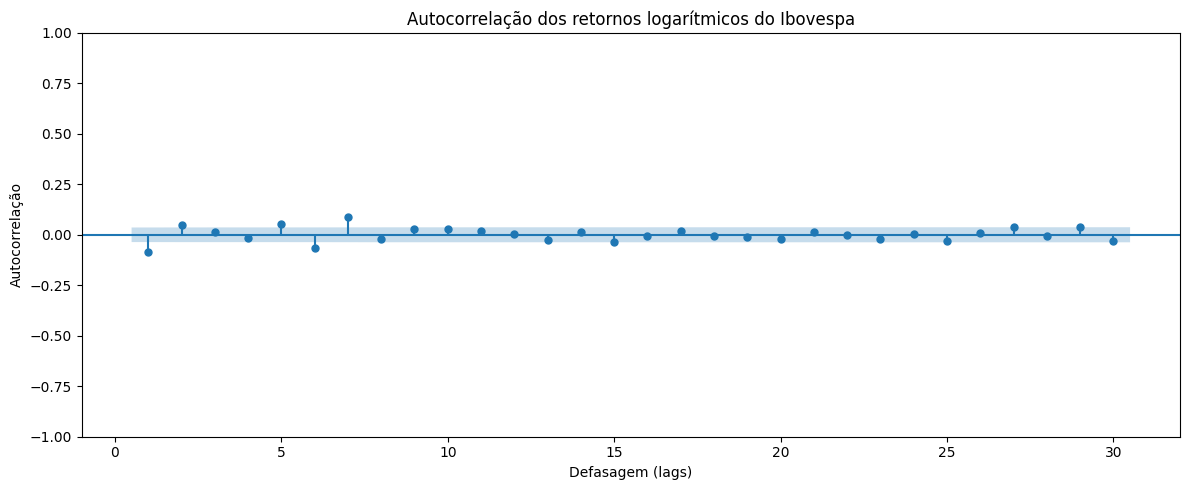

In [32]:
from statsmodels.graphics.tsaplots import plot_acf

fig, ax = plt.subplots(figsize=(12, 5))
plot_acf(retornos, lags=30, alpha=0.05, zero=False, ax=ax)
ax.set_title("Autocorrelação dos retornos logarítmicos do Ibovespa")
ax.set_xlabel("Defasagem (lags)")
ax.set_ylabel("Autocorrelação")
plt.tight_layout()
plt.show()

## Autocorrelação dos retornos logarítmicos do Ibovespa

### O que o gráfico mostra

- As autocorrelações dos retornos logarítmicos ficam muito próximas de zero em todos os lags (1 a 30), dentro ou na borda da faixa de confiança de 95% (área azul clara).
- Esse é o resultado esperado para retornos de índices financeiros: pouca ou nenhuma autocorrelação linear, em linha com a **hipótese de mercado eficiente na forma fraca**. Os retornos passados não ajudam a prever os retornos futuros.
- Alguns lags (como 1, 5 e 7) tocam ou ultrapassam levemente a faixa de confiança. Com 30 lags e 95% de confiança, é normal que 1 ou 2 saiam da faixa por acaso, então isso não indica dependência relevante.
- Com `zero=False`, o lag 0 (que seria sempre igual a 1) não é exibido.

### Interpretação

Os retornos do Ibovespa se comportam de forma muito próxima a um ruído sem memória linear. Isso **não** significa que a série seja totalmente independente: a ausência de autocorrelação nos retornos não exclui dependência em outros momentos, como a volatilidade.

### Próximo passo

Plotar o ACF dos **retornos absolutos** (`retornos.abs()`) ou dos **retornos ao quadrado** (`retornos**2`). Nesses casos, espera-se uma autocorrelação positiva e de decaimento lento, que é a assinatura do **agrupamento de volatilidade** (*volatility clustering*). O contraste entre os dois gráficos mostra que os retornos são pouco previsíveis, mas a volatilidade é.

## 6. Validação e limitações

A análise dos retornos financeiros do Ibovespa foi desenvolvida considerando procedimentos de validação matemática, estatística e computacional, com o objetivo de garantir maior consistência aos resultados e reconhecer as limitações dos métodos utilizados.

### 1. Validação matemática dos retornos

Inicialmente, foram utilizados dois indicadores para representar as variações dos preços do Ibovespa: o retorno simples e o retorno logarítmico.

O retorno simples é definido por:

\[
$R_t = \frac{P_t}{P_{t-1}}-1$
\]

Enquanto o retorno logarítmico é calculado por:

\[
$r_t = \ln\left(\frac{P_t}{P_{t-1}}\right)$
\]

A relação entre essas duas medidas é dada por:

\[
$r_t = \ln(1+R_t)$
\]

Uma propriedade importante dos retornos logarítmicos é a aditividade temporal. Para períodos consecutivos:

\[
$\sum_{t=1}^{n}r_t = \ln\left(\frac{P_n}{P_0}\right)$
\]

Essa propriedade foi utilizada como critério de validação da implementação computacional, verificando a equivalência entre a soma dos retornos logarítmicos e o retorno logarítmico acumulado diretamente a partir dos preços.

A validação matemática permite verificar se os cálculos estão coerentes com as definições teóricas utilizadas.

### 2. Consistência e tratamento dos dados

Antes da realização das análises estatísticas, os dados foram organizados cronologicamente e os retornos logarítmicos foram preparados para os cálculos posteriores.

Foram considerados os seguintes procedimentos:

- Organização das observações em ordem cronológica;
- Conversão dos retornos para valores numéricos;
- Identificação de valores ausentes;
- Tratamento de valores infinitos;
- Exclusão de observações inválidas para os cálculos estatísticos.

Também é importante considerar que o cálculo dos retornos depende da existência de preços válidos em períodos consecutivos. Dessa forma, a primeira observação da série não possui retorno calculável, pois não existe um preço anterior para comparação.

Esses procedimentos contribuem para evitar que valores inválidos comprometam as estatísticas e os gráficos produzidos.

### 3. Validação da análise das distribuições estatísticas

A análise das distribuições foi realizada por meio de medidas estatísticas descritivas, buscando identificar características que não são evidentes apenas pela observação dos preços.

Entre os indicadores analisados, destacam-se a média, a dispersão, a assimetria, a curtose e os quantis.

Os resultados obtidos para a assimetria e a curtose excedente foram:

- Assimetria: -1,249240;
- Curtose excedente: 18,133451.

A assimetria negativa indica uma distribuição com maior extensão na cauda esquerda, enquanto a curtose excedente elevada indica uma distribuição com caudas mais pesadas do que as de uma distribuição normal.

Também foram observados os seguintes quantis:

- Quantil de 1%: -0,034181;
- Quantil de 99%: 0,036006;
- Intervalo interquartil (IQR): 0,015226.

Esses resultados mostram que a distribuição dos retornos apresenta características que merecem atenção, especialmente em relação à assimetria e à ocorrência de valores extremos.

Entretanto, essas estatísticas, isoladamente, não permitem determinar a distribuição probabilística que melhor representa os retornos. Para isso, seria necessário complementar a investigação com ajustes de distribuições e testes estatísticos apropriados.

### 4. Validação da análise de volatilidade

A volatilidade foi investigada por meio do desvio-padrão dos retornos logarítmicos, utilizando janelas móveis de 21 e 63 pregões.

Os resultados descritivos foram:

| Estatística | Janela de 21 pregões | Janela de 63 pregões |
|---|---:|---:|
| Média | 0,012961 | 0,013267 |
| Desvio-padrão | 0,007110 | 0,006297 |
| Mínimo | 0,004196 | 0,006423 |
| Mediana | 0,011733 | 0,012181 |
| Máximo | 0,081449 | 0,051632 |

As médias das duas janelas foram relativamente próximas. Entretanto, a janela de 21 pregões apresentou maior dispersão e valor máximo superior ao da janela de 63 pregões.

Esse comportamento é coerente com a diferença entre os tamanhos das janelas: períodos menores respondem mais rapidamente às oscilações recentes, enquanto períodos maiores tendem a suavizar as variações de curto prazo.

A diferença na quantidade de observações válidas também é esperada, pois uma janela de 63 pregões exige um histórico maior para produzir a primeira estimativa de volatilidade.

### 5. Limitações da análise

Apesar dos procedimentos adotados, existem limitações importantes que precisam ser consideradas na interpretação dos resultados.

**Limitações dos dados**

A análise depende da qualidade, da frequência e do período histórico da série utilizada. Alterações na fonte, falhas de registro ou diferenças no tratamento dos preços podem modificar os resultados.

Além disso, a análise dos retornos históricos não incorpora automaticamente fatores externos que influenciam o mercado, como decisões econômicas, acontecimentos políticos, mudanças nas taxas de juros e eventos internacionais.

**Limitações estatísticas**

A média e o desvio-padrão são medidas importantes, mas não descrevem integralmente o comportamento de distribuições assimétricas e com caudas pesadas.

A hipótese de normalidade não deve ser assumida sem investigação. A presença de assimetria e curtose elevada indica que uma distribuição normal pode não representar adequadamente todas as características dos retornos observados.

**Limitações da volatilidade móvel**

A volatilidade calculada por janelas móveis depende diretamente do tamanho da janela escolhido.

Janelas menores podem apresentar maior sensibilidade às oscilações recentes, enquanto janelas maiores suavizam as variações. Portanto, os resultados não representam uma medida única e definitiva do risco do mercado.

**Limitações de interpretação**

A identificação de relações estatísticas não implica, necessariamente, causalidade. Da mesma forma, padrões observados no histórico não garantem que o mesmo comportamento será mantido no futuro.

Os resultados devem ser interpretados como evidências empíricas referentes ao período analisado, e não como previsões determinísticas do comportamento futuro do Ibovespa.

### 6. Considerações finais das validações

As validações matemáticas e computacionais, associadas às medidas estatísticas e à análise da volatilidade, fornecem uma base consistente para compreender o comportamento dos retornos financeiros.

Entretanto, a interpretação dos resultados exige considerar as características da série, a escolha dos parâmetros e as limitações dos métodos empregados.

O reconhecimento dessas limitações é parte fundamental da análise científica, pois permite distinguir os resultados efetivamente sustentados pelos dados das hipóteses que ainda precisam de investigação.